# PulmoSight 06 — Model Diagnostics: Overfitting, Robustness & Shortcut Checks

In [1]:
import json, math, os, random, time
from collections import deque
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.io as tvio
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if DEVICE.type == "cuda" and torch.cuda.is_bf16_supported() else torch.float16
IMAGE_SIZE, MEAN, STD = 512, 0.449, 0.226
CLASSES = ["normal", "tb"]
SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything()
torch.backends.cudnn.benchmark = True
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

print(f"Project root : {ROOT}")
print(f"PyTorch      : {torch.__version__}")
print(f"Device       : {DEVICE} ({torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'})")
print(f"AMP dtype    : {AMP_DTYPE}")

Project root : F:\Projects\pulmoSight\TB Project
PyTorch      : 2.11.0+cu128
Device       : cuda (NVIDIA GeForce RTX 4060 Laptop GPU)
AMP dtype    : torch.bfloat16


In [2]:
def read_xray(path):
    """Decode a cached 8-bit grayscale PNG -> uint8 tensor [1, H, W]."""
    img = tvio.decode_image(tvio.read_file(str(path)), mode=tvio.ImageReadMode.GRAY)
    if img.shape[-2:] != (IMAGE_SIZE, IMAGE_SIZE):
        img = F.interpolate(img[None].float(), size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear",
                            antialias=True, align_corners=False)[0].round().clamp(0, 255).to(torch.uint8)
    return img


class XrayLoader:
    """Thread-pool batch loader.

    Windows notebooks cannot pickle notebook-defined Datasets into DataLoader worker
    processes, so we decode PNGs with threads (decoding releases the GIL) and do all
    augmentation on the GPU instead.
    """
    def __init__(self, frame, batch_size=32, shuffle=False, drop_last=False, threads=12, prefetch=6, seed=SEED):
        self.paths = [ROOT / p for p in frame["path"]]
        self.labels = frame["label"].to_numpy(dtype=np.int64)
        self.batch_size, self.shuffle, self.drop_last = batch_size, shuffle, drop_last
        self.threads, self.prefetch = threads, prefetch
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        n = len(self.paths)
        return n // self.batch_size if self.drop_last else math.ceil(n / self.batch_size)

    def __iter__(self):
        n = len(self.paths)
        order = self.rng.permutation(n) if self.shuffle else np.arange(n)
        batches = [order[i:i + self.batch_size] for i in range(0, n, self.batch_size)]
        if self.drop_last and len(batches[-1]) < self.batch_size:
            batches = batches[:-1]
        with ThreadPoolExecutor(self.threads) as pool:
            pending, it = deque(), iter(batches)
            submit = lambda b: (b, [pool.submit(read_xray, self.paths[i]) for i in b])
            for _ in range(self.prefetch):
                b = next(it, None)
                if b is not None:
                    pending.append(submit(b))
            while pending:
                b, futures = pending.popleft()
                nxt = next(it, None)
                if nxt is not None:
                    pending.append(submit(nxt))
                x = torch.stack([f.result() for f in futures])
                yield x, torch.from_numpy(self.labels[b])


def gpu_augment(x):
    """Random affine (+-7 deg, +-4% shift, 0.93-1.07 zoom) + brightness/contrast jitter, on GPU."""
    b, dev = x.size(0), x.device
    u = lambda: torch.rand(b, device=dev) * 2 - 1
    angle, scale = u() * math.radians(7), 1 + u() * 0.07
    tx, ty = u() * 0.08, u() * 0.08            # grid spans [-1, 1] -> 4% of the image
    cos, sin = torch.cos(angle) / scale, torch.sin(angle) / scale
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    bright = 1 + u().view(b, 1, 1, 1) * 0.15
    contrast = 1 + u().view(b, 1, 1, 1) * 0.15
    x = x * bright
    m = x.mean(dim=(2, 3), keepdim=True)
    return ((x - m) * contrast + m).clamp(0, 1)


def prepare_batch(x, augment=False):
    x = x.to(DEVICE, non_blocking=True).float().div_(255)
    if augment:
        x = gpu_augment(x)
    return ((x - MEAN) / STD).contiguous(memory_format=torch.channels_last)


splits = pd.read_csv(ROOT / "splits" / "splits.csv")
train_df = splits[splits.split == "train"].reset_index(drop=True)
val_df = splits[splits.split == "val"].reset_index(drop=True)
test_df = splits[splits.split == "test"].reset_index(drop=True)
print(splits.groupby(["split", "label"]).size().unstack().rename(columns=dict(enumerate(CLASSES))))

label  normal    tb
split              
test      861   820
train    6860  6585
val       850   809


In [3]:
def autocast():
    return torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type == "cuda")


@torch.no_grad()
def predict_logits(model, loader):
    model.eval()
    logits, labels = [], []
    for x, y in loader:
        with autocast():
            out = model(prepare_batch(x))
        logits.append(out.float().cpu()); labels.append(y)
    return torch.cat(logits).numpy(), torch.cat(labels).numpy()


def binary_metrics(logits, labels, threshold=0.5):
    p = torch.from_numpy(logits).softmax(1)[:, 1].numpy()
    pred = p >= threshold
    pos = labels == 1
    tp, tn = int((pred & pos).sum()), int((~pred & ~pos).sum())
    fp, fn = int((pred & ~pos).sum()), int((~pred & pos).sum())
    return {"auroc": float(roc_auc_score(labels, p)), "acc": (tp + tn) / len(labels),
            "sensitivity": tp / max(tp + fn, 1), "specificity": tn / max(tn + fp, 1)}


def fit(model, train_loader, val_loader, optimizer, scheduler, epochs, criterion, ckpt_path, meta,
        patience=6, history=None, stage="", before_epoch=None):
    """Train with early stopping on validation AUROC. Saves the best checkpoint to ckpt_path."""
    history = [] if history is None else history
    best = max([h["val_auroc"] for h in history], default=-1.0)
    bad = 0
    start = len(history) + 1
    for epoch in range(start, start + epochs):
        t0 = time.time()
        model.train()
        if before_epoch:
            before_epoch(model)
        loss_sum = torch.zeros((), device=DEVICE); correct = torch.zeros((), device=DEVICE); seen = 0
        for x, y in train_loader:
            x, y = prepare_batch(x, augment=True), y.to(DEVICE, non_blocking=True)
            with autocast():
                out = model(x)
            loss = criterion(out.float(), y)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            optimizer.step()
            scheduler.step()
            loss_sum += loss.detach() * y.size(0); correct += (out.argmax(1) == y).sum(); seen += y.size(0)

        val_logits, val_labels = predict_logits(model, val_loader)
        val_loss = F.cross_entropy(torch.from_numpy(val_logits), torch.from_numpy(val_labels)).item()
        m = binary_metrics(val_logits, val_labels)
        row = {"epoch": epoch, "stage": stage, "train_loss": loss_sum.item() / seen, "train_acc": correct.item() / seen,
               "val_loss": val_loss, "val_acc": m["acc"], "val_auroc": m["auroc"],
               "val_sensitivity": m["sensitivity"], "val_specificity": m["specificity"],
               "lr": optimizer.param_groups[-1]["lr"], "seconds": time.time() - t0}
        history.append(row)
        flag = ""
        if m["auroc"] > best:
            best, bad, flag = m["auroc"], 0, "  * best, saved"
            torch.save({**meta, "state_dict": model.state_dict(), "epoch": epoch, "val_metrics": m}, ckpt_path)
        else:
            bad += 1
        print(f"Epoch {epoch:02d} {stage:>9} | train loss {row['train_loss']:.4f} acc {row['train_acc']:.3f} | "
              f"val loss {val_loss:.4f} acc {m['acc']:.3f} AUROC {m['auroc']:.4f} "
              f"sens {m['sensitivity']:.3f} spec {m['specificity']:.3f} | {row['seconds']:.0f}s{flag}")
        if bad >= patience:
            print(f"Early stopping: no AUROC improvement for {patience} epochs.")
            break
    return history


def plot_history(history, title):
    h = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    axes[0].plot(h.epoch, h.train_loss, "o-", label="train"); axes[0].plot(h.epoch, h.val_loss, "o-", label="val")
    axes[0].set(title="Loss", xlabel="epoch"); axes[0].legend()
    axes[1].plot(h.epoch, h.train_acc, "o-", label="train"); axes[1].plot(h.epoch, h.val_acc, "o-", label="val")
    axes[1].set(title="Accuracy", xlabel="epoch"); axes[1].legend()
    axes[2].plot(h.epoch, h.val_auroc, "o-", color="tab:green", label="val AUROC")
    axes[2].plot(h.epoch, h.val_sensitivity, "--", label="val sensitivity")
    axes[2].plot(h.epoch, h.val_specificity, "--", label="val specificity")
    best = h.loc[h.val_auroc.idxmax()]
    axes[2].axvline(best.epoch, color="gray", ls=":", label=f"best epoch {int(best.epoch)}")
    axes[2].set(title="Validation metrics", xlabel="epoch"); axes[2].legend()
    fig.suptitle(title, fontsize=14, weight="bold"); fig.tight_layout()
    return fig

In [4]:
class SqueezeExcite(nn.Module):
    """Channel attention: learn which feature maps matter for this image."""
    def __init__(self, channels, reduction=8):
        super().__init__()
        self.fc = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(channels, channels // reduction, 1),
                                nn.SiLU(), nn.Conv2d(channels // reduction, channels, 1), nn.Sigmoid())

    def forward(self, x):
        return x * self.fc(x)


class ConvBNAct(nn.Sequential):
    def __init__(self, cin, cout, k=3, stride=1, act=True):
        super().__init__(nn.Conv2d(cin, cout, k, stride, k // 2, bias=False), nn.BatchNorm2d(cout),
                         nn.SiLU() if act else nn.Identity())


class ResidualSEBlock(nn.Module):
    """3x3 conv -> 3x3 conv -> squeeze-excite, plus a (projected) skip connection."""
    def __init__(self, cin, cout, stride=1, drop_path=0.0):
        super().__init__()
        self.body = nn.Sequential(ConvBNAct(cin, cout, 3, stride), ConvBNAct(cout, cout, 3, act=False),
                                  SqueezeExcite(cout))
        self.skip = (nn.Identity() if stride == 1 and cin == cout else
                     nn.Sequential(nn.AvgPool2d(stride) if stride > 1 else nn.Identity(),
                                   ConvBNAct(cin, cout, 1, act=False)))
        self.drop_path = drop_path
        self.act = nn.SiLU()

    def forward(self, x):
        out = self.body(x)
        if self.training and self.drop_path > 0:   # stochastic depth
            keep = torch.rand(out.size(0), 1, 1, 1, device=out.device) >= self.drop_path
            out = out * keep / (1 - self.drop_path)
        return self.act(out + self.skip(x))


class PulmoNet(nn.Module):
    """Custom CNN for 1-channel 512x512 chest X-rays, trained from scratch.

    512 -> stem (128) -> stage1 (128) -> stage2 (64) -> stage3 (32) -> stage4 (16) -> GAP -> FC
    """
    def __init__(self, widths=(48, 96, 160, 256), depths=(2, 2, 3, 2), num_classes=2, drop=0.3, drop_path=0.1):
        super().__init__()
        self.stem = nn.Sequential(ConvBNAct(1, 32, 5, 2), ConvBNAct(32, 32, 3), ConvBNAct(32, widths[0], 3, 2))
        total, idx, cin, stages = sum(depths), 0, widths[0], []
        for i, (w, d) in enumerate(zip(widths, depths)):
            blocks = []
            for j in range(d):
                stride = 2 if (j == 0 and i > 0) else 1
                blocks.append(ResidualSEBlock(cin, w, stride, drop_path * idx / max(total - 1, 1)))
                cin, idx = w, idx + 1
            stages.append(nn.Sequential(*blocks))
        self.stage1, self.stage2, self.stage3, self.stage4 = stages
        self.head_conv = ConvBNAct(cin, 512, 1)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(drop), nn.Linear(512, num_classes))
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01); nn.init.zeros_(m.bias)

    def features(self, x):
        x = self.stem(x)
        x = self.stage4(self.stage3(self.stage2(self.stage1(x))))
        return self.head_conv(x)

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

In [5]:
from torchvision import models

def build_efficientnet_b0(pretrained=True):
    """ImageNet EfficientNet-B0 adapted to 1-channel X-rays (RGB stem filters summed)."""
    weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
    model = models.efficientnet_b0(weights=weights)
    stem = model.features[0][0]
    gray = nn.Conv2d(1, stem.out_channels, stem.kernel_size, stem.stride, stem.padding, bias=False)
    with torch.no_grad():
        gray.weight.copy_(stem.weight.sum(dim=1, keepdim=True))
    model.features[0][0] = gray
    model.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(1280, 2))
    return model

## 0. Load both trained models

In [6]:
def load_model(arch):
    ckpt = torch.load(ROOT / "models" / arch / "best.pth", map_location="cpu", weights_only=False)
    model = PulmoNet() if arch == "pulmonet" else build_efficientnet_b0(pretrained=False)
    model.load_state_dict(ckpt["state_dict"])
    return model.to(DEVICE, memory_format=torch.channels_last).eval(), ckpt

MODELS = {"PulmoNet (scratch)": "pulmonet", "EfficientNet-B0 (transfer)": "efficientnet_b0"}
COLORS = {"PulmoNet (scratch)": "#7C3AED", "EfficientNet-B0 (transfer)": "#059669"}
models_ = {n: load_model(a)[0] for n, a in MODELS.items()}
hist = {n: pd.DataFrame(json.loads((ROOT / "models" / a / "history.json").read_text())) for n, a in MODELS.items()}
loaders = {"train": XrayLoader(train_df, 64), "val": XrayLoader(val_df, 64), "test": XrayLoader(test_df, 64)}

## 1. Clean train / val / test metrics

In [7]:
from sklearn.metrics import log_loss
scores, probs = {}, {}
for n, m in models_.items():
    probs[n] = {}
    for split, loader in loaders.items():
        t0 = time.time()
        lg, y = predict_logits(m, loader)
        p = torch.from_numpy(lg).softmax(1)[:, 1].numpy()
        probs[n][split] = (p, y)
        bm = binary_metrics(lg, y)
        scores[(n, split)] = {"AUROC": bm["auroc"], "Accuracy@0.5": bm["acc"], "Log-loss": log_loss(y, p),
                              "Sensitivity@0.5": bm["sensitivity"], "Specificity@0.5": bm["specificity"]}
    print(f"scored {n}")
table = pd.DataFrame(scores).T
display(table.style.format("{:.4f}").background_gradient(subset=["AUROC"], cmap="Greens"))

gap = pd.DataFrame({n: {"train − test AUROC": scores[(n, "train")]["AUROC"] - scores[(n, "test")]["AUROC"],
                        "train − test accuracy": scores[(n, "train")]["Accuracy@0.5"] - scores[(n, "test")]["Accuracy@0.5"],
                        "test / train log-loss": scores[(n, "test")]["Log-loss"] / scores[(n, "train")]["Log-loss"],
                        "val − test AUROC": scores[(n, "val")]["AUROC"] - scores[(n, "test")]["AUROC"]} for n in MODELS}).T
display(gap.style.format("{:+.4f}"))

scored PulmoNet (scratch)


scored EfficientNet-B0 (transfer)


,train − test AUROC,train − test accuracy,test / train log-loss,val − test AUROC
PulmoNet (scratch),+0.0699,+0.0955,+1.8610,+0.0187
EfficientNet-B0 (transfer),+0.0529,+0.0889,+2.1767,+0.0061


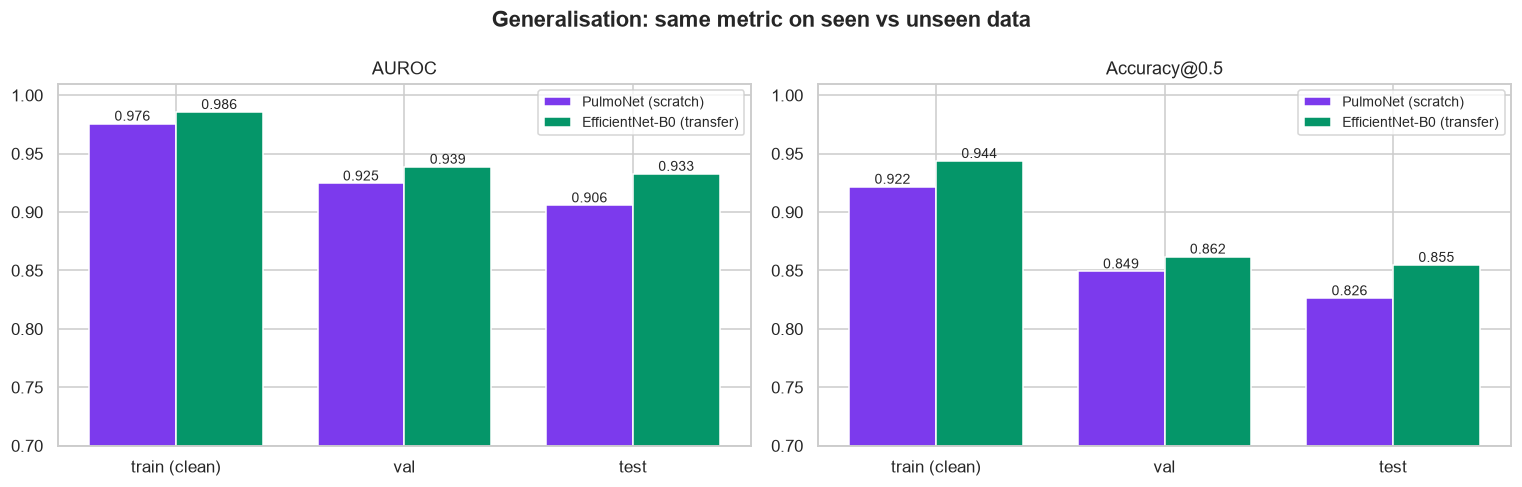

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
x = np.arange(3)
for i, n in enumerate(MODELS):
    for ax, metric in zip(axes, ["AUROC", "Accuracy@0.5"]):
        vals = [scores[(n, s)][metric] for s in ["train", "val", "test"]]
        bars = ax.bar(x + (i - 0.5) * 0.38, vals, 0.38, color=COLORS[n], label=n)
        ax.bar_label(bars, fmt="%.3f", fontsize=9)
for ax, metric in zip(axes, ["AUROC", "Accuracy@0.5"]):
    ax.set_xticks(x, ["train (clean)", "val", "test"]); ax.set_ylim(0.7, 1.01); ax.set_title(metric); ax.legend(fontsize=9)
plt.suptitle("Generalisation: same metric on seen vs unseen data", weight="bold"); plt.tight_layout(); plt.show()

## 2. When did overfitting start?

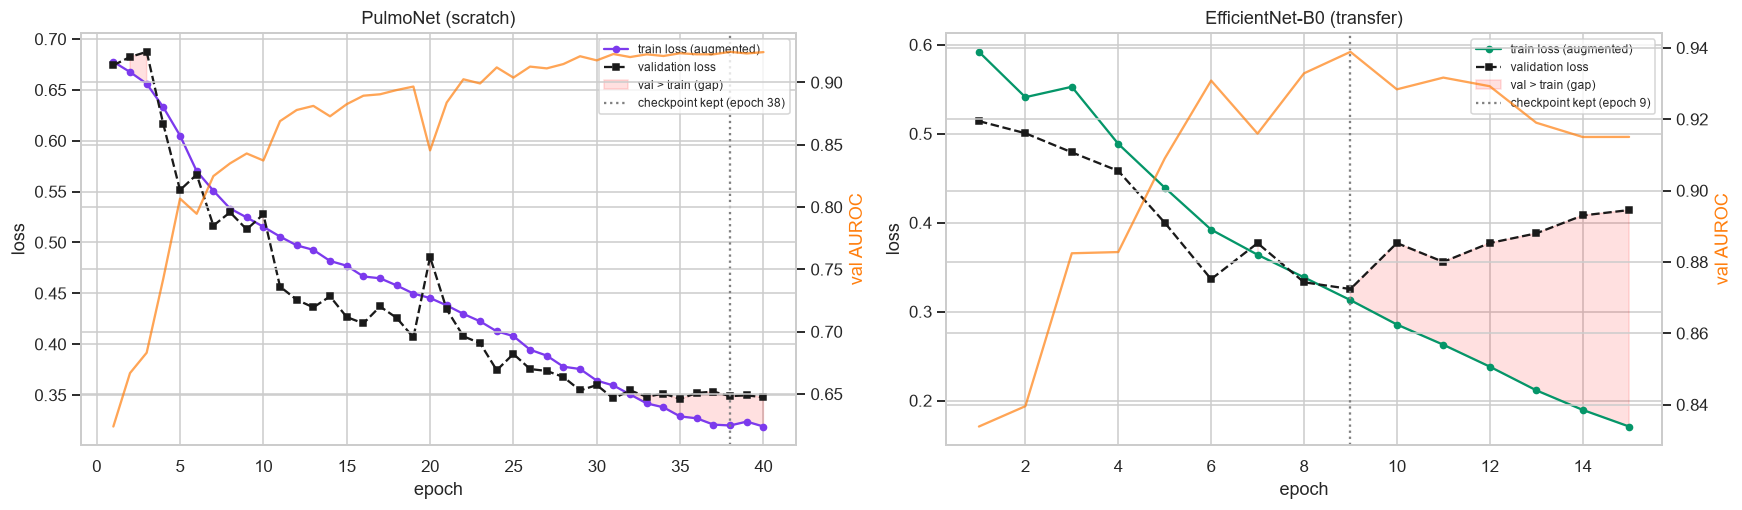

PulmoNet (scratch)
  best val AUROC at epoch 38; lowest val loss at epoch 35
  from epoch 35 to 40: train loss 0.329 -> 0.319, val loss 0.346 -> 0.348, train acc 0.888 -> 0.892
EfficientNet-B0 (transfer)
  best val AUROC at epoch 9; lowest val loss at epoch 9
  from epoch 9 to 15: train loss 0.313 -> 0.171, val loss 0.325 -> 0.414, train acc 0.898 -> 0.976


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for ax, (n, h) in zip(axes, hist.items()):
    best = int(h.loc[h.val_auroc.idxmax(), "epoch"])
    ax.plot(h.epoch, h.train_loss, "o-", ms=4, color=COLORS[n], label="train loss (augmented)")
    ax.plot(h.epoch, h.val_loss, "s--", ms=4, color="k", label="validation loss")
    ax.fill_between(h.epoch, h.train_loss, h.val_loss, where=h.val_loss > h.train_loss, color="red", alpha=0.12, label="val > train (gap)")
    ax.axvline(best, color="gray", ls=":", label=f"checkpoint kept (epoch {best})")
    ax2 = ax.twinx(); ax2.plot(h.epoch, h.val_auroc, color="tab:orange", alpha=0.7); ax2.set_ylabel("val AUROC", color="tab:orange")
    ax.set(title=n, xlabel="epoch", ylabel="loss"); ax.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.savefig(ROOT / "results" / "comparison" / "overfitting_curves.png", dpi=150, bbox_inches="tight"); plt.show()

for n, h in hist.items():
    best_row = h.loc[h.val_auroc.idxmax()]
    min_val_loss = h.loc[h.val_loss.idxmin()]
    last = h.iloc[-1]
    print(f"{n}\n  best val AUROC at epoch {int(best_row.epoch)}; lowest val loss at epoch {int(min_val_loss.epoch)}\n"
          f"  from epoch {int(min_val_loss.epoch)} to {int(last.epoch)}: train loss {min_val_loss.train_loss:.3f} -> {last.train_loss:.3f}, "
          f"val loss {min_val_loss.val_loss:.3f} -> {last.val_loss:.3f}, train acc {min_val_loss.train_acc:.3f} -> {last.train_acc:.3f}")

## 3. Memorisation: how confident is each model on images it trained on vs new images?

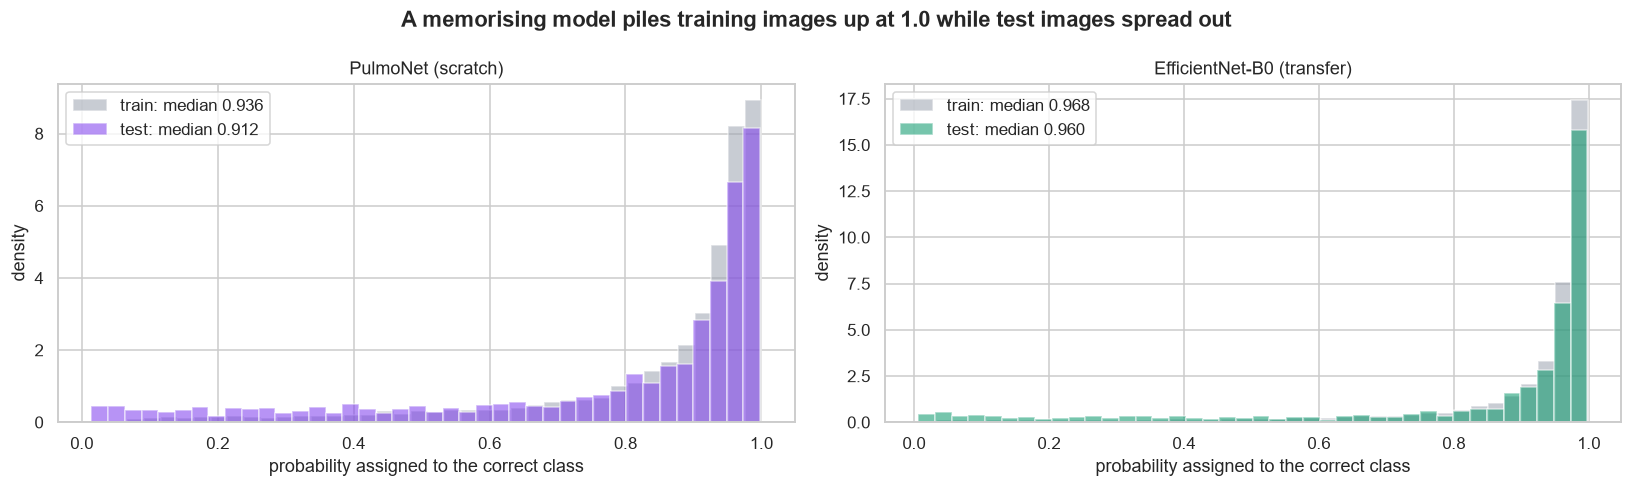

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, n in zip(axes, MODELS):
    for split, color in [("train", "#9CA3AF"), ("test", COLORS[n])]:
        p, y = probs[n][split]
        conf_correct = np.where(y == 1, p, 1 - p)     # probability given to the TRUE class
        ax.hist(conf_correct, bins=40, density=True, alpha=0.55, color=color, label=f"{split}: median {np.median(conf_correct):.3f}")
    ax.set(title=n, xlabel="probability assigned to the correct class", ylabel="density"); ax.legend()
plt.suptitle("A memorising model piles training images up at 1.0 while test images spread out", weight="bold")
plt.tight_layout(); plt.show()

## 4. Robustness to image-quality changes

In [11]:
test_u8 = torch.cat([x for x, _ in XrayLoader(test_df, 128)]).to(DEVICE)          # [N,1,512,512] uint8
y_test = test_df.label.to_numpy()

def gaussian_blur(x, sigma):
    k = int(2 * round(3 * sigma) + 1); r = torch.arange(k, device=x.device) - k // 2
    g = torch.exp(-r.float() ** 2 / (2 * sigma ** 2)); g = (g / g.sum()).view(1, 1, 1, k)
    x = F.conv2d(F.pad(x, (k // 2, k // 2, 0, 0), mode="reflect"), g)
    return F.conv2d(F.pad(x, (0, 0, k // 2, k // 2), mode="reflect"), g.transpose(2, 3))

def rotate(x, deg):
    a = math.radians(deg); theta = torch.tensor([[math.cos(a), -math.sin(a), 0], [math.sin(a), math.cos(a), 0]], device=x.device)
    return F.grid_sample(x, F.affine_grid(theta.expand(x.size(0), 2, 3), x.shape, align_corners=False), align_corners=False)

g = torch.Generator(device=DEVICE).manual_seed(0)
CORRUPTIONS = {
    "Gaussian noise":    (lambda x, s: (x + torch.randn(x.shape, device=x.device, generator=g) * s).clamp(0, 1), [0.02, 0.05, 0.10]),
    "Blur":              (gaussian_blur, [1.0, 2.0, 4.0]),
    "Low contrast":      (lambda x, s: (x - x.mean((2, 3), keepdim=True)) * s + x.mean((2, 3), keepdim=True), [0.8, 0.6, 0.4]),
    "Brightness shift":  (lambda x, s: (x + s).clamp(0, 1), [0.05, 0.10, 0.20]),
    "Rotation":          (rotate, [5, 10, 15]),
    "Low resolution":    (lambda x, s: F.interpolate(F.interpolate(x, size=s, mode="area"), size=IMAGE_SIZE, mode="bilinear"), [256, 128, 64]),
    "Gamma (exposure)":  (lambda x, s: x.clamp(1e-4, 1) ** s, [0.8, 0.6, 1.5]),
}

@torch.no_grad()
def auroc_on(model, transform=None, bs=64):
    out = []
    for i in range(0, len(test_u8), bs):
        x = test_u8[i:i + bs].float() / 255
        if transform is not None: x = transform(x)
        x = ((x - MEAN) / STD).contiguous(memory_format=torch.channels_last)
        with autocast(): out.append(model(x).float().softmax(1)[:, 1].cpu())
    return roc_auc_score(y_test, torch.cat(out).numpy())

rob = []
for n, m in models_.items():
    clean = auroc_on(m)
    rob.append({"model": n, "corruption": "clean", "level": 0, "strength": "-", "AUROC": clean})
    for cname, (fn, levels) in CORRUPTIONS.items():
        for lvl, s in enumerate(levels, 1):
            rob.append({"model": n, "corruption": cname, "level": lvl, "strength": s, "AUROC": auroc_on(m, lambda x: fn(x, s))})
rob = pd.DataFrame(rob)
pivot = rob[rob.corruption != "clean"].pivot_table(index=["corruption", "level", "strength"], columns="model", values="AUROC")
display(pivot.style.format("{:.3f}").background_gradient(cmap="RdYlGn", vmin=0.5, vmax=0.95))

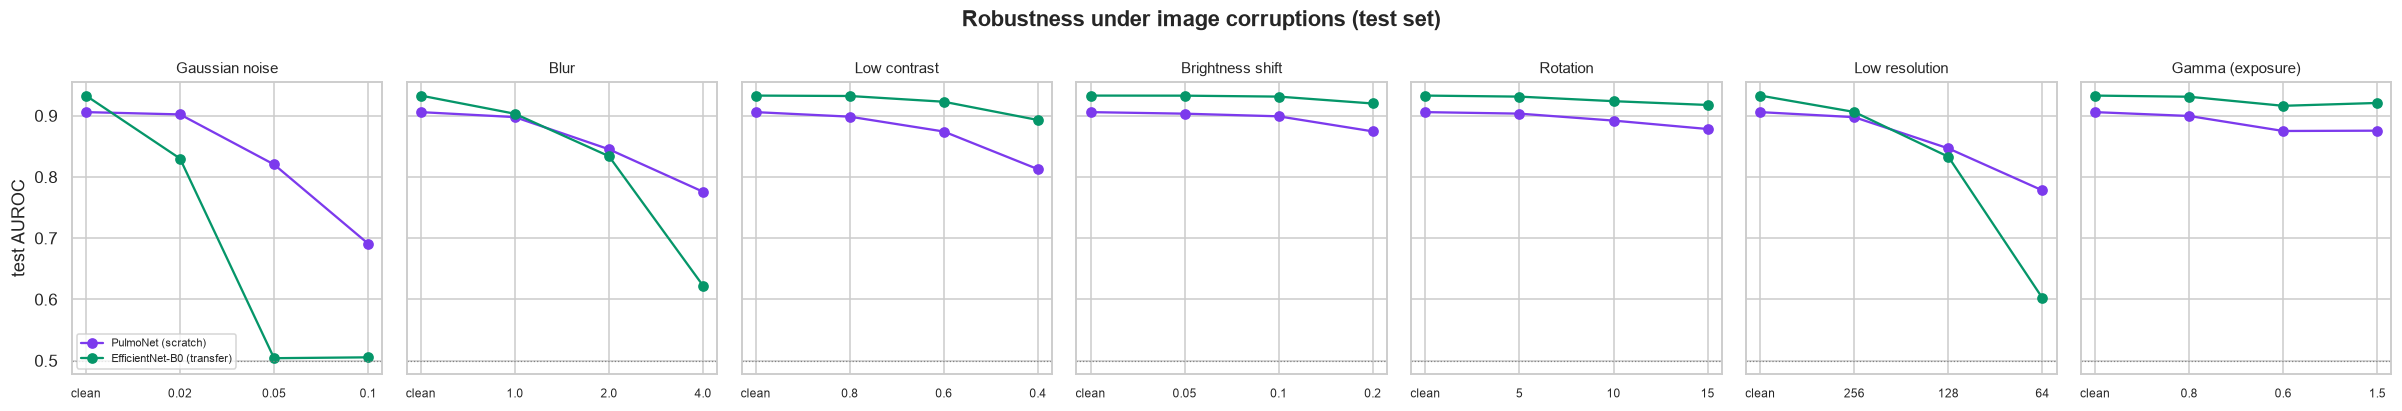

,mean,min,clean,mean drop
model,,,,
EfficientNet-B0 (transfer),0.8387,0.504,0.9328,0.0941
PulmoNet (scratch),0.8590,0.691,0.9058,0.0468


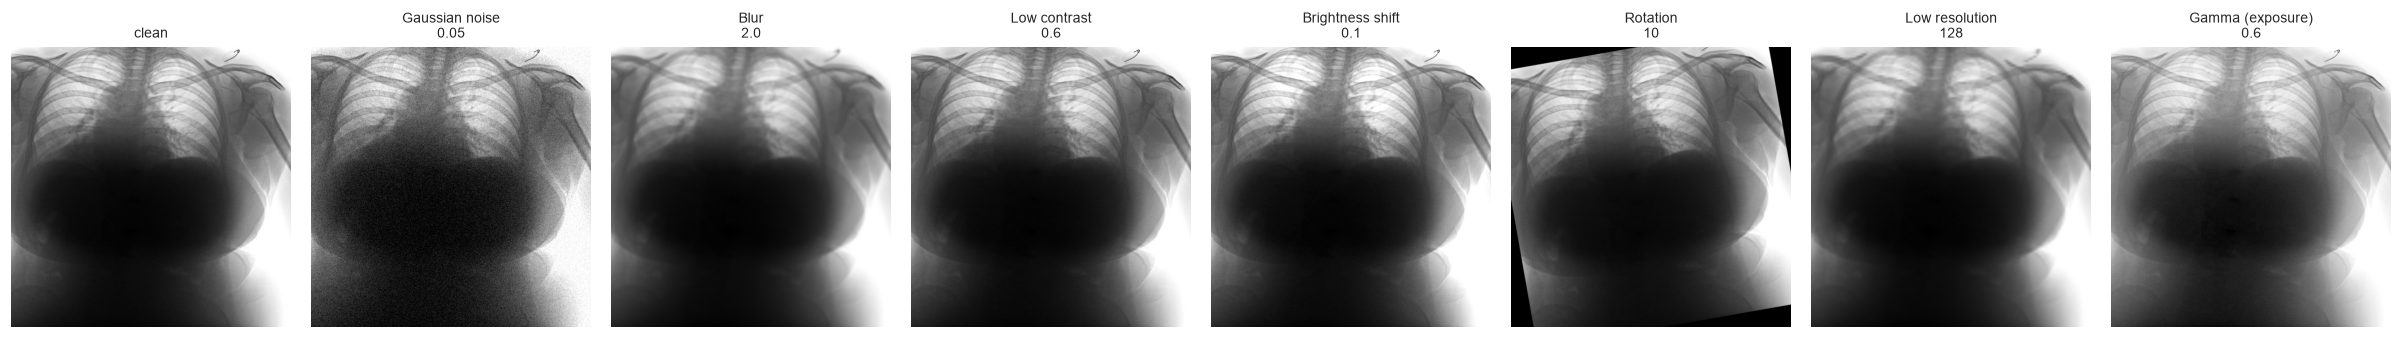

In [12]:
fig, axes = plt.subplots(1, len(CORRUPTIONS), figsize=(22, 3.8), sharey=True)
for ax, cname in zip(axes, CORRUPTIONS):
    for n in MODELS:
        d = rob[(rob.model == n) & ((rob.corruption == cname) | (rob.corruption == "clean"))].sort_values("level")
        ax.plot(d.level, d.AUROC, "o-", color=COLORS[n], label=n)
    ax.set_xticks([0, 1, 2, 3], ["clean"] + [str(s) for s in CORRUPTIONS[cname][1]], fontsize=8)
    ax.set_title(cname, fontsize=10); ax.axhline(0.5, color="gray", ls=":", lw=0.8)
axes[0].set_ylabel("test AUROC"); axes[0].legend(fontsize=7, loc="lower left")
plt.suptitle("Robustness under image corruptions (test set)", weight="bold"); plt.tight_layout()
plt.savefig(ROOT / "results" / "comparison" / "robustness.png", dpi=150, bbox_inches="tight"); plt.show()

summary_rob = rob[rob.corruption != "clean"].groupby("model").AUROC.agg(["mean", "min"])
summary_rob["clean"] = rob[rob.corruption == "clean"].set_index("model").AUROC
summary_rob["mean drop"] = summary_rob["clean"] - summary_rob["mean"]
display(summary_rob.round(4))

# Show what the corruptions look like
sample = test_u8[:1].float() / 255
fig, axes = plt.subplots(1, len(CORRUPTIONS) + 1, figsize=(22, 3.4))
axes[0].imshow(sample[0, 0].cpu(), cmap="gray"); axes[0].set_title("clean", fontsize=9)
for ax, (cname, (fn, levels)) in zip(axes[1:], CORRUPTIONS.items()):
    ax.imshow(fn(sample, levels[1])[0, 0].clamp(0, 1).cpu(), cmap="gray"); ax.set_title(f"{cname}\n{levels[1]}", fontsize=9)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Shortcut check — is the model looking at the lungs?

,PulmoNet (scratch),EfficientNet-B0 (transfer)
original,0.906,0.933
lungs hidden (only outside visible),0.721,0.851
outside hidden (only lungs visible),0.796,0.877


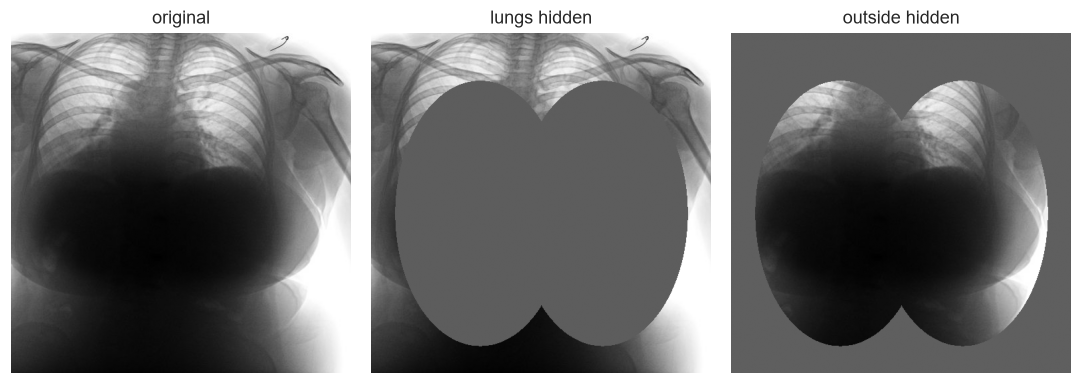

In [13]:
yy, xx = torch.meshgrid(torch.arange(IMAGE_SIZE, device=DEVICE), torch.arange(IMAGE_SIZE, device=DEVICE), indexing="ij")
ell = lambda cx: (((xx - IMAGE_SIZE * cx) / (IMAGE_SIZE * 0.25)) ** 2 + ((yy - IMAGE_SIZE * 0.53) / (IMAGE_SIZE * 0.39)) ** 2) <= 1
LUNG = (ell(0.32) | ell(0.68)).float()[None, None]
fill = lambda x: x.mean((2, 3), keepdim=True)    # occlude with the image's mean grey, not black

occl = {}
for n, m in models_.items():
    occl[n] = {"original": auroc_on(m),
               "lungs hidden (only outside visible)": auroc_on(m, lambda x: x * (1 - LUNG) + fill(x) * LUNG),
               "outside hidden (only lungs visible)": auroc_on(m, lambda x: x * LUNG + fill(x) * (1 - LUNG))}
occl = pd.DataFrame(occl)
display(occl.style.format("{:.3f}"))

s = test_u8[:1].float() / 255
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
for ax, (t, img) in zip(axes, [("original", s), ("lungs hidden", s * (1 - LUNG) + fill(s) * LUNG), ("outside hidden", s * LUNG + fill(s) * (1 - LUNG))]):
    ax.imshow(img[0, 0].cpu(), cmap="gray"); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()

Lung ellipses cover 56.0% of the image (random-attention baseline)


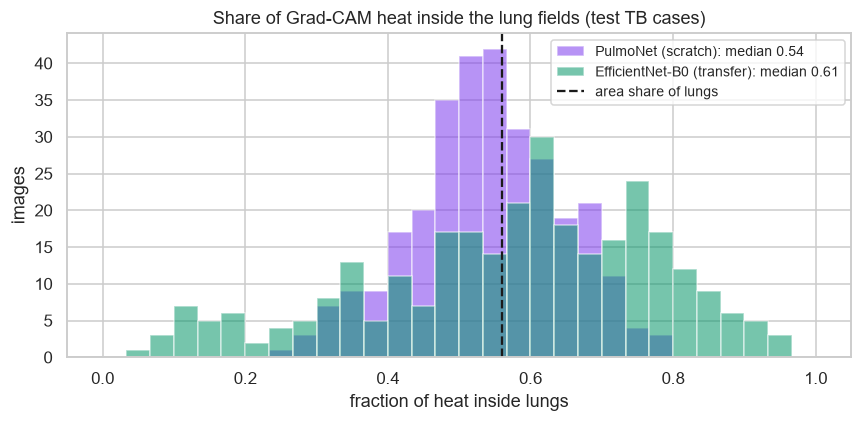

In [14]:
def grad_cam(model, layer, x):
    store = {}
    def fwd(_m, _i, out):
        store["act"] = out
        out.register_hook(lambda g_: store.__setitem__("grad", g_))
    h = layer.register_forward_hook(fwd)
    try:
        model.zero_grad(set_to_none=True)
        model(x)[:, 1].sum().backward()
        w = store["grad"].float().mean((2, 3), keepdim=True)
        cam = (w * store["act"].float()).sum(1, keepdim=True).relu()
        return F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False).detach()
    finally:
        h.remove()

LAYERS = {"PulmoNet (scratch)": models_["PulmoNet (scratch)"].head_conv,
          "EfficientNet-B0 (transfer)": models_["EfficientNet-B0 (transfer)"].features[-1]}
tb_idx = np.where(y_test == 1)[0][:300]
cam_frac = {}
for n, m in models_.items():
    fr = []
    for i in range(0, len(tb_idx), 16):
        x = ((test_u8[tb_idx[i:i + 16]].float() / 255 - MEAN) / STD).contiguous(memory_format=torch.channels_last)
        cam = grad_cam(m, LAYERS[n], x)
        fr.append(((cam * LUNG).sum((1, 2, 3)) / (cam.sum((1, 2, 3)) + 1e-8)).cpu())
    cam_frac[n] = torch.cat(fr).numpy()
print(f"Lung ellipses cover {LUNG.mean().item():.1%} of the image (random-attention baseline)")
fig, ax = plt.subplots(figsize=(8, 4))
for n, f in cam_frac.items():
    ax.hist(f, bins=30, range=(0, 1), alpha=0.55, color=COLORS[n], label=f"{n}: median {np.median(f):.2f}")
ax.axvline(LUNG.mean().item(), color="k", ls="--", label="area share of lungs")
ax.set(title="Share of Grad-CAM heat inside the lung fields (test TB cases)", xlabel="fraction of heat inside lungs", ylabel="images")
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

## 6. Do the models know when they don't know?

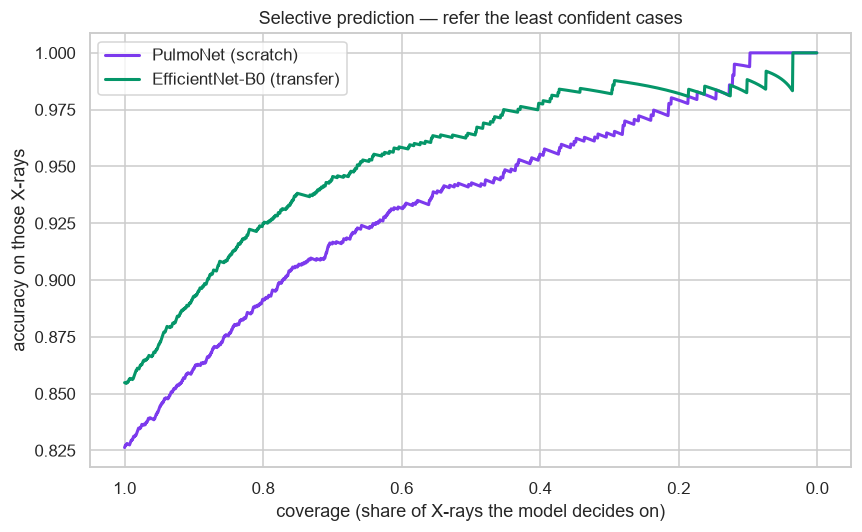

model,EfficientNet-B0 (transfer),PulmoNet (scratch)
coverage,,
90%,0.893,0.861
80%,0.925,0.891
70%,0.946,0.917
50%,0.964,0.942
100%,0.855,0.826


In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
cov_rows = []
for n in MODELS:
    p, y = probs[n]["test"]
    conf = np.abs(p - 0.5); order = np.argsort(-conf)
    correct = ((p >= 0.5) == y)[order]
    coverage = np.arange(1, len(y) + 1) / len(y)
    acc = np.cumsum(correct) / np.arange(1, len(y) + 1)
    ax.plot(coverage, acc, color=COLORS[n], lw=2, label=n)
    for c in [1.0, 0.9, 0.8, 0.7, 0.5]:
        cov_rows.append({"model": n, "coverage": f"{c:.0%}", "accuracy": acc[int(c * len(y)) - 1], "referred to human": f"{1 - c:.0%}"})
ax.set(xlabel="coverage (share of X-rays the model decides on)", ylabel="accuracy on those X-rays",
       title="Selective prediction — refer the least confident cases"); ax.invert_xaxis(); ax.legend()
plt.tight_layout(); plt.savefig(ROOT / "results" / "comparison" / "selective_prediction.png", dpi=150, bbox_inches="tight"); plt.show()
display(pd.DataFrame(cov_rows).pivot(index="coverage", columns="model", values="accuracy").sort_index(ascending=False).style.format("{:.3f}"))

## 7. Save the diagnostics

In [16]:
diag = {"split_scores": {f"{n}|{s}": v for (n, s), v in scores.items()},
        "gaps": gap.round(5).to_dict(), "robustness": rob.round(5).to_dict("records"),
        "occlusion": occl.round(5).to_dict(), "gradcam_lung_fraction_median": {n: float(np.median(f)) for n, f in cam_frac.items()},
        "lung_area_share": float(LUNG.mean().item())}
(ROOT / "results" / "comparison" / "diagnostics.json").write_text(json.dumps(diag, indent=2, default=float))
print("Saved diagnostics.json")

Saved diagnostics.json
